# Penalized logistic regression

Ridge, lasso and elastic net logistic regression for predicting whether an unplanned
New York hospital admission lasts more than 7 days. Decisions are in
`docs/notes/2026-11-10-model-comparison-plan.md` and
`docs/notes/2026-11-11-penalized-logistic.md`. The data, cohort, split, cleaning and
encoder come from `analysis/common.py`, and `analysis/baseline_model.py` walks
through them.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score

from analysis import common

RESULTS_DIR = common.RESULTS_DIR / "penalized_logistic"

## Step 1: Setup

The same training set, features and folds as the baseline. The recalibration and
test sets aren't used here.

In [2]:
train, recal, test = common.load_splits()
X, y = train[common.FEATURES], train["y"]
print(f"{len(train):,} training stays, {y.mean():.1%} stayed more than 7 days")
print(f"{len(common.FEATURES)} features")

360,000 training stays, 23.1% stayed more than 7 days
17 features


## Step 2: The model

Elastic net logistic regression adds a penalty on the size of the coefficients to the
usual fit. The penalty is a mix of two kinds, set by `l1_ratio`:

- **`l1_ratio = 0` is ridge.** It shrinks every coefficient toward zero, but never
  all the way.
- **`l1_ratio = 1` is lasso.** It can set coefficients exactly to zero, which drops
  those levels from the model.
- **In between is elastic net,** which does some of both.

`C` sets how much the penalty matters. Small `C` is a strong penalty. Large `C` is a
weak one, and as `C` grows the model approaches the unpenalized baseline. The fit
adds up the error over every row but the penalty doesn't grow with the data, so with
288,000 rows per fold even `C = 1` is a very weak penalty.

One grid covers all three penalties:

- `l1_ratio` in {0, 0.5, 1}
- 11 values of `C` from 1e-5 to 1, evenly spaced on a log scale

That's 33 settings × 5 folds = 165 fits. Every setting uses full one-hot encoding with
no level dropped, and no scaling, since every column is a 0/1 dummy. `saga` is the
only scikit-learn solver that handles every `l1_ratio`.

In [3]:
L1_RATIOS = [0.0, 0.5, 1.0]
PENALTY_NAMES = {0.0: "Ridge", 0.5: "Elastic net", 1.0: "Lasso"}
CS = np.logspace(-5, 0, 11)
MAX_ITERATIONS = 1_000


def make_model(l1_ratio, C):
    return LogisticRegression(
        solver="saga",
        l1_ratio=l1_ratio,
        C=C,
        max_iter=MAX_ITERATIONS,
        random_state=common.SEED,
    )

## Step 3: Tune

The encoder is fit on each fold's training part only. It doesn't depend on `C` or
`l1_ratio`, so each fold is encoded once and reused for all 33 settings. New levels
in a validation fold make the encoder warn, as expected, so we silence that one
warning.

The 165 fits run in parallel. For each one we save the validation AUC and Brier, the
number of iterations, whether it converged, how many coefficients are nonzero and the
fit time. To recompute, delete `results/penalized_logistic/tuning.csv`.

In [4]:
def encode_folds():
    """Encode each fold, fitting the encoder on the fold's training part only."""
    folds = []
    for fold, (fit_rows, validation_rows) in enumerate(
        common.FOLDS.split(X, y), start=1
    ):
        encoder = common.make_encoder()
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Found unknown categories")
            X_fit = encoder.fit_transform(X.iloc[fit_rows])
            X_validation = encoder.transform(X.iloc[validation_rows])
        folds.append(
            {
                "fold": fold,
                "X_fit": X_fit,
                "y_fit": y.iloc[fit_rows].to_numpy(),
                "X_validation": X_validation,
                "y_validation": y.iloc[validation_rows].to_numpy(),
            }
        )
    return folds


def fit_one(fold, l1_ratio, C):
    """Fit one setting on one fold and score it on the validation part."""
    model = make_model(l1_ratio, C)
    start = time.perf_counter()
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=ConvergenceWarning)
        model.fit(fold["X_fit"], fold["y_fit"])
    seconds = time.perf_counter() - start
    risk = model.predict_proba(fold["X_validation"])[:, 1]
    iterations = model.n_iter_[0]
    return {
        "l1_ratio": l1_ratio,
        "C": C,
        "fold": fold["fold"],
        "auc": roc_auc_score(fold["y_validation"], risk),
        "brier": brier_score_loss(fold["y_validation"], risk),
        "nonzero": int((model.coef_ != 0).sum()),
        "columns": model.coef_.shape[1],
        "iterations": iterations,
        "converged": iterations < MAX_ITERATIONS,
        "seconds": seconds,
    }


def run_tuning():
    folds = encode_folds()
    rows = Parallel(n_jobs=-1, verbose=5)(
        delayed(fit_one)(fold, l1_ratio, C)
        for l1_ratio in L1_RATIOS
        for C in CS
        for fold in folds
    )
    return {"tuning": pd.DataFrame(rows)}


tuning = common.load_or_compute(
    {"tuning": RESULTS_DIR / "tuning.csv"}, run_tuning
)["tuning"]

assert len(tuning) == len(L1_RATIOS) * len(CS) * common.FOLDS.get_n_splits()
print(f"{tuning['seconds'].sum() / 60:.0f} minutes of fitting in total")
print(f"{(~tuning['converged']).sum()} of {len(tuning)} fits didn't converge")
print(tuning[~tuning["converged"]].to_string(index=False))

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:    5.7s


[Parallel(n_jobs=-1)]: Done  56 tasks      | elapsed:  1.7min


[Parallel(n_jobs=-1)]: Done 146 tasks      | elapsed: 31.8min


[Parallel(n_jobs=-1)]: Done 165 out of 165 | elapsed: 42.4min finished


Computed and saved results
300 minutes of fitting in total
4 of 165 fits didn't converge
 l1_ratio        C  fold      auc    brier  nonzero  columns  iterations  converged     seconds
      0.5 0.316228     2 0.773392 0.144700      547      610        1000      False 1428.463289
      0.5 0.316228     3 0.772253 0.144946      538      607        1000      False 1407.941332
      0.5 0.316228     4 0.771462 0.144840      549      611        1000      False 1334.578368
      0.5 0.316228     5 0.774883 0.144725      547      610        1000      False 1322.374076


## Step 4: Tuning curve

Mean and SD of each score across the 5 folds, for every setting. The baseline's CV
AUC and Brier, from `results/baseline_logistic/cv_scores.csv`, are the reference.

In [5]:
summary = (
    tuning.groupby(["l1_ratio", "C"])
    .agg(
        auc=("auc", "mean"),
        auc_sd=("auc", "std"),
        brier=("brier", "mean"),
        brier_sd=("brier", "std"),
        nonzero=("nonzero", "mean"),
        converged=("converged", "all"),
        seconds=("seconds", "mean"),
    )
    .reset_index()
)
summary.insert(0, "penalty", summary["l1_ratio"].map(PENALTY_NAMES))

baseline_scores = pd.read_csv(common.RESULTS_DIR / "baseline_logistic" / "cv_scores.csv")
baseline_auc = baseline_scores["auc"].mean()
baseline_brier = baseline_scores["brier"].mean()
print(f"Baseline: AUC {baseline_auc:.4f}, Brier {baseline_brier:.4f}")

print(summary.drop(columns="l1_ratio").to_string(index=False, float_format="{:.4g}".format))

Baseline: AUC 0.7734, Brier 0.1447
    penalty         C    auc   auc_sd  brier  brier_sd  nonzero  converged  seconds
      Ridge     1e-05  0.676 0.002127 0.1745 2.479e-05    609.4       True    3.985
      Ridge 3.162e-05 0.6932 0.002235 0.1704 6.076e-05    609.4       True    3.805
      Ridge    0.0001 0.7149 0.002241  0.164 0.0001259    609.4       True    3.716
      Ridge 0.0003162 0.7326 0.002147  0.157 0.0002155    609.4       True    3.771
      Ridge     0.001 0.7475 0.002044 0.1518 0.0003008    609.4       True    3.741
      Ridge  0.003162 0.7595 0.002037 0.1485  0.000359    609.4       True    9.972
      Ridge      0.01 0.7674 0.002063 0.1464 0.0003875    609.4       True    30.92
      Ridge   0.03162 0.7715 0.001989 0.1453 0.0003865    609.4       True    51.03
      Ridge       0.1 0.7731 0.001851 0.1448 0.0003669    609.4       True    48.54
      Ridge    0.3162 0.7735 0.001731 0.1447 0.0003466    609.4       True     4.12
      Ridge         1 0.7737 0.001662 0.1

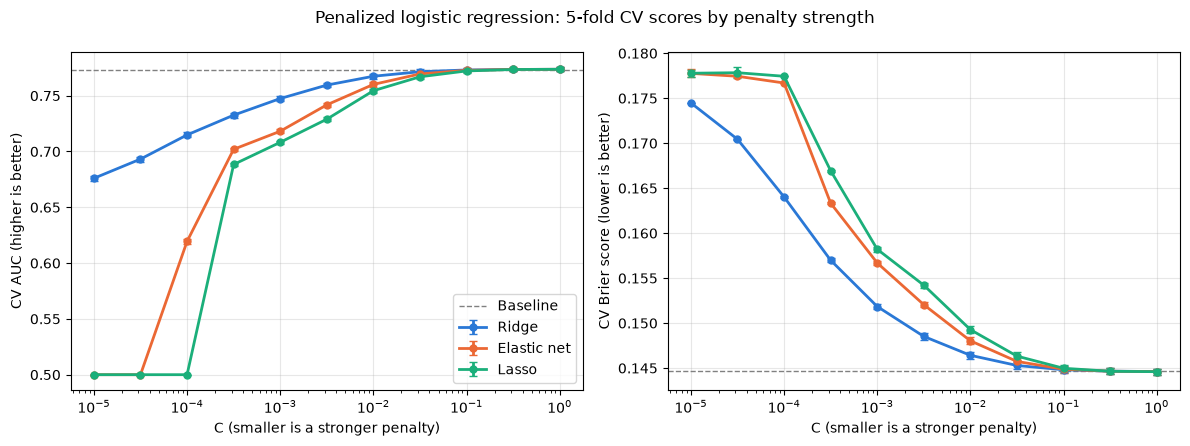

In [6]:
COLORS = {0.0: "#2a78d6", 0.5: "#eb6834", 1.0: "#1baf7a"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, score, baseline_value, label in [
    (axes[0], "auc", baseline_auc, "CV AUC (higher is better)"),
    (axes[1], "brier", baseline_brier, "CV Brier score (lower is better)"),
]:
    ax.axhline(baseline_value, color="gray", linestyle="--", linewidth=1, label="Baseline")
    for l1_ratio in L1_RATIOS:
        rows = summary[summary["l1_ratio"] == l1_ratio]
        ax.errorbar(
            rows["C"],
            rows[score],
            yerr=rows[f"{score}_sd"],
            color=COLORS[l1_ratio],
            marker="o",
            markersize=5,
            linewidth=2,
            capsize=3,
            label=PENALTY_NAMES[l1_ratio],
        )
    ax.set_xscale("log")
    ax.set_xlabel("C (smaller is a stronger penalty)")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
axes[0].legend(loc="lower right")
fig.suptitle("Penalized logistic regression: 5-fold CV scores by penalty strength")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "tuning.png", dpi=150)

### Best setting for each penalty

The highest mean CV AUC within each penalty. If the best `C` is at either end of the
grid, the grid should be extended that way.

In [7]:
best = summary.loc[summary.groupby("l1_ratio")["auc"].idxmax()].copy()
best["at_edge"] = best["C"].isin([CS.min(), CS.max()])
best["auc_vs_baseline"] = best["auc"] - baseline_auc
print(
    best[
        [
            "penalty",
            "C",
            "auc",
            "auc_sd",
            "auc_vs_baseline",
            "brier",
            "nonzero",
            "at_edge",
        ]
    ].to_string(index=False, float_format="{:.4g}".format)
)

    penalty  C    auc   auc_sd  auc_vs_baseline  brier  nonzero  at_edge
      Ridge  1 0.7737 0.001662        0.0002302 0.1446    609.4     True
Elastic net  1 0.7737 0.001658        0.0002404 0.1446      568     True
      Lasso  1 0.7737 0.001663        0.0002422 0.1446    556.2     True
